# T28. Frente de Pareto y elección de red

**Regla fijada para el ajuste.** Entre los radios principales (200, 250 y 300 m) se elige la red evaluada con menos estaciones que llegue al 80 % de viajes con ambos extremos cubiertos. Los empates se resuelven por menor P90 de distancia de todos los extremos, mayor número de viajes cubiertos y menor radio. Los 400 m se incluyen como sensibilidad. Si ninguna cumple el 80 %, la regla prioriza cobertura y después número de estaciones.

Se conserva una alternativa con el presupuesto inmediatamente inferior del mismo radio y, cuando existe, una con menor radio que cumpla el objetivo. Esta elección se hace con el ajuste antes de examinar rutas peatonales o viajes reservados.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from comun.figuras import guardar_figura, plt
from redes import METODOS, OBJETIVO_PCT, RADIOS, RADIOS_PRINCIPALES, guardar, leer

base25 = leer("T25_barrido").rename(columns={"viajes_ajuste": "viajes"})
# Una misma red de T25 puede evaluarse con varios radios.
base25["network_id"] = base25["network_id"] + "_r" + base25["radio_m"].astype(str)
columnas = ["network_id", "metodo", "radio_m", "k", "viajes", "viajes_cubiertos",
            "pct_viajes_cubiertos", "d_media_m", "d_p90_m"]
redes = pd.concat([base25[columnas], leer("T26_resultados")[columnas], leer("T27_resultados")[columnas]],
                  ignore_index=True)
assert redes["network_id"].is_unique


def pareto(datos):
    ejes = datos[["k", "viajes_cubiertos", "d_p90_m"]].to_numpy()
    ejes[:, 1] *= -1
    d = np.all(ejes[:, None, :] <= ejes[None, :, :], axis=2) & np.any(ejes[:, None, :] < ejes[None, :, :], axis=2)
    return ~d.any(axis=0)


redes["pareto_radio"] = False
for _, grupo in redes.groupby("radio_m"):
    redes.loc[grupo.index, "pareto_radio"] = pareto(grupo)
principales = redes.loc[redes["radio_m"].isin(RADIOS_PRINCIPALES)]
redes["pareto_principal"] = False
redes.loc[principales.index, "pareto_principal"] = pareto(principales)

orden = ["k", "d_p90_m", "viajes_cubiertos", "radio_m", "network_id"]
asc = [True, True, False, True, True]
cumplen = principales.loc[principales["viajes_cubiertos"] * 100 >= OBJETIVO_PCT * principales["viajes"]]
principal = (cumplen.sort_values(orden, ascending=asc).iloc[0] if len(cumplen)
             else principales.sort_values(["viajes_cubiertos", "k", "d_p90_m", "radio_m", "network_id"],
                                          ascending=[False, True, True, True, True]).iloc[0])

baratas = principales.loc[(principales["radio_m"] == principal["radio_m"]) & (principales["k"] < principal["k"])]
radio_menor = cumplen.loc[cumplen["radio_m"] < principal["radio_m"]]
finalistas = [(principal, "recomendada")]
if len(baratas):
    alternativa = baratas.sort_values(["k", "viajes_cubiertos", "d_p90_m", "network_id"],
                                     ascending=[False, False, True, True]).iloc[0]
    finalistas.append((alternativa, "menos_estaciones"))
if len(radio_menor):
    finalistas.append((radio_menor.sort_values(orden, ascending=asc).iloc[0], "radio_menor"))
redes["rol"] = redes["network_id"].map({r["network_id"]: rol for r, rol in finalistas}).fillna("")
guardar(redes, "T28_comparacion")
elegidas = redes.loc[redes["rol"].ne("")].copy()
guardar(elegidas, "T28_finalistas")

candidatas = pd.concat([leer("T26_redes"), leer("T27_redes")], ignore_index=True)
r25 = leer("T25_redes")
estaciones = []
for red, _ in finalistas:
    red_id = red["network_id"]
    if red["metodo"] in {"kmedoids", "kmeans"}:
        pos = r25.loc[r25["network_id"].eq(red_id.rsplit("_r", 1)[0])].assign(network_id=red_id)
    else:
        pos = candidatas.loc[candidatas["network_id"].eq(red_id)]
    assert len(pos) == pos["station_id"].nunique() == red["k"]
    estaciones.append(pos[["network_id", "station_id", "lon", "lat"]])
guardar(pd.concat(estaciones, ignore_index=True), "T28_estaciones")
display(elegidas[["rol", "metodo", "radio_m", "k", "pct_viajes_cubiertos", "d_p90_m"]].round(3))

,rol,metodo,radio_m,k,pct_viajes_cubiertos,d_p90_m
167,radio_menor,lscp,250,225,80.036,265.646
168,recomendada,lscp,300,159,80.030,309.778
208,menos_estaciones,mclp,300,158,79.797,310.434


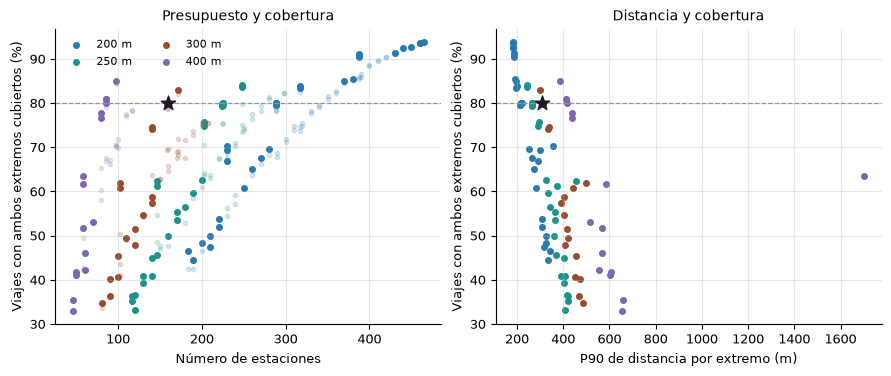

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.65), layout="constrained")
colores = dict(zip(RADIOS, ["#287ab1", "#1b938b", "#9a4b30", "#7f66ad"]))
for radio, g in redes.groupby("radio_m"):
    fuerte = g.loc[g["pareto_radio"]]
    axes[0].scatter(g["k"], g["pct_viajes_cubiertos"], s=9, alpha=.18, color=colores[radio])
    axes[0].scatter(fuerte["k"], fuerte["pct_viajes_cubiertos"], s=16, color=colores[radio],
                    label=f"{radio} m")
    axes[1].scatter(fuerte["d_p90_m"], fuerte["pct_viajes_cubiertos"], s=16, color=colores[radio])
for eje, x in zip(axes, ("k", "d_p90_m")):
    eje.scatter(principal[x], principal["pct_viajes_cubiertos"], marker="*", color="#191c23", s=115, zorder=6)
    eje.axhline(OBJETIVO_PCT, color="#8a99a5", linestyle="--", lw=.9)
    eje.set(ylabel="Viajes con ambos extremos cubiertos (%)")
axes[0].set(xlabel="Número de estaciones", title="Presupuesto y cobertura")
axes[1].set(xlabel="P90 de distancia por extremo (m)", title="Distancia y cobertura")
axes[0].legend(frameon=False, ncol=2)
guardar_figura(fig, "movilidad", "T28_pareto")

**Lectura.** El frente conserva las redes a las que ninguna otra mejora simultáneamente en número de estaciones, cobertura y P90. La estrella identifica la red elegida en el ajuste por la regla previa. `T28_estaciones.csv` fija los emplazamientos que reciben T29 y T30.